# Setup & Load Untouched Raw Data (Kaggle CSV)

In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    precision_score, recall_score, classification_report, precision_recall_curve
)
from lightgbm import LGBMClassifier
import shap

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("outputs", exist_ok=True)

# Adjust path automatically whether notebook is in root or src/
CSV_PATH = "data/raw/credit_risk_dataset.csv"
if not os.path.exists(CSV_PATH) and os.path.exists("../data/raw/credit_risk_dataset.csv"):
    CSV_PATH = "../data/raw/credit_risk_dataset.csv"

df_raw = pd.read_csv(CSV_PATH)
print(f"Raw Dataset Shape: {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns")
df_raw.head()

C:\Users\adjis\anaconda3\envs\100-days-real-world-ml\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Raw Dataset Shape: 32,581 rows, 12 columns


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


# EDA 1: Schema, Duplicates & Missing Value Profiling

In [2]:
print(f"Exact Duplicate Rows: {df_raw.duplicated().sum()} ({df_raw.duplicated().mean():.2%})")

audit_records = []
for col in df_raw.columns:
    null_count = df_raw[col].isnull().sum()
    audit_records.append({
        "Column": col,
        "Dtype": str(df_raw[col].dtype),
        "Null_Count": null_count,
        "Null_Pct (%)": round((null_count / len(df_raw)) * 100, 2),
        "Unique_Values": df_raw[col].nunique(),
        "Sample_Values": str(df_raw[col].dropna().unique()[:4]),
    })

audit_df = pd.DataFrame(audit_records)
display(audit_df)

# Check if missingness in loan_int_rate or person_emp_length is associated with default rate
for col in ["loan_int_rate", "person_emp_length"]:
    missing_flag = df_raw[col].isnull()
    default_when_missing = df_raw.loc[missing_flag, "loan_status"].mean() * 100
    default_when_present = df_raw.loc[~missing_flag, "loan_status"].mean() * 100
    print(f"-> '{col}' Missing Default Rate: {default_when_missing:.2f}% vs Present Default Rate: {default_when_present:.2f}%")

Exact Duplicate Rows: 165 (0.51%)


,Column,Dtype,Null_Count,Null_Pct (%),Unique_Values,Sample_Values
0,person_age,int64,0,0.00,58,[22 21 25 23]
1,person_income,int64,0,0.00,4295,[59000 9600 65500 54400]
2,person_home_ownership,str,0,0.00,4,"<StringArray>\n['RENT', 'OWN', 'MORTGAGE', 'OT..."
3,person_emp_length,float64,895,2.75,36,[123. 5. 1. 4.]
4,loan_intent,str,0,0.00,6,"<StringArray>\n['PERSONAL', 'EDUCATION', 'MEDI..."
5,loan_grade,str,0,0.00,7,"<StringArray>\n['D', 'B', 'C', 'A']\nLength: 4..."
6,loan_amnt,int64,0,0.00,753,[35000 1000 5500 2500]
7,loan_int_rate,float64,3116,9.56,348,[16.02 11.14 12.87 15.23]
8,loan_status,int64,0,0.00,2,[1 0]
9,loan_percent_income,float64,0,0.00,77,[0.59 0.1 0.57 0.53]


-> 'loan_int_rate' Missing Default Rate: 20.67% vs Present Default Rate: 21.94%
-> 'person_emp_length' Missing Default Rate: 31.51% vs Present Default Rate: 21.54%


# EDA 2: Statistical Summary, Impossible Outliers & Visual Risk Profiling

Target Variable ('loan_status') Distribution (0 = Non-Default, 1 = Default):


,Count,Percentage (%)
loan_status,,
0,25473,78.18
1,7108,21.82


,count,mean,std,min,50%,max,skewness,IQR_Outliers
person_age,32581.0,27.73,6.35,20.00,26.00,144.00,2.58,1494
person_income,32581.0,66074.85,61983.12,4000.00,55000.00,6000000.00,32.87,1484
person_emp_length,31686.0,4.79,4.14,0.00,4.00,123.00,2.61,853
loan_amnt,32581.0,9589.37,6322.09,500.00,8000.00,35000.00,1.19,1689
loan_int_rate,29465.0,11.01,3.24,5.42,10.99,23.22,0.21,6
loan_percent_income,32581.0,0.17,0.11,0.00,0.15,0.83,1.06,651
cb_person_cred_hist_length,32581.0,5.80,4.06,2.00,4.00,30.00,1.66,1142


Anomalous rows with person_age > 100               : 5 rows (Max age: 144)
Anomalous rows with impossible employment length   : 2 rows (Max emp_length: 123.0)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
81,144,250000,RENT,4.0,VENTURE,C,4800,13.57,0,0.02,N,3
183,144,200000,MORTGAGE,4.0,EDUCATION,B,6000,11.86,0,0.03,N,2
575,123,80004,RENT,2.0,EDUCATION,B,20400,10.25,0,0.25,N,3
747,123,78000,RENT,7.0,VENTURE,B,20000,NaN,0,0.26,N,4
32297,144,6000000,MORTGAGE,12.0,PERSONAL,C,5000,12.73,0,0.00,N,25
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
210,21,192000,MORTGAGE,123.0,VENTURE,A,20000,6.54,0,0.10,N,4


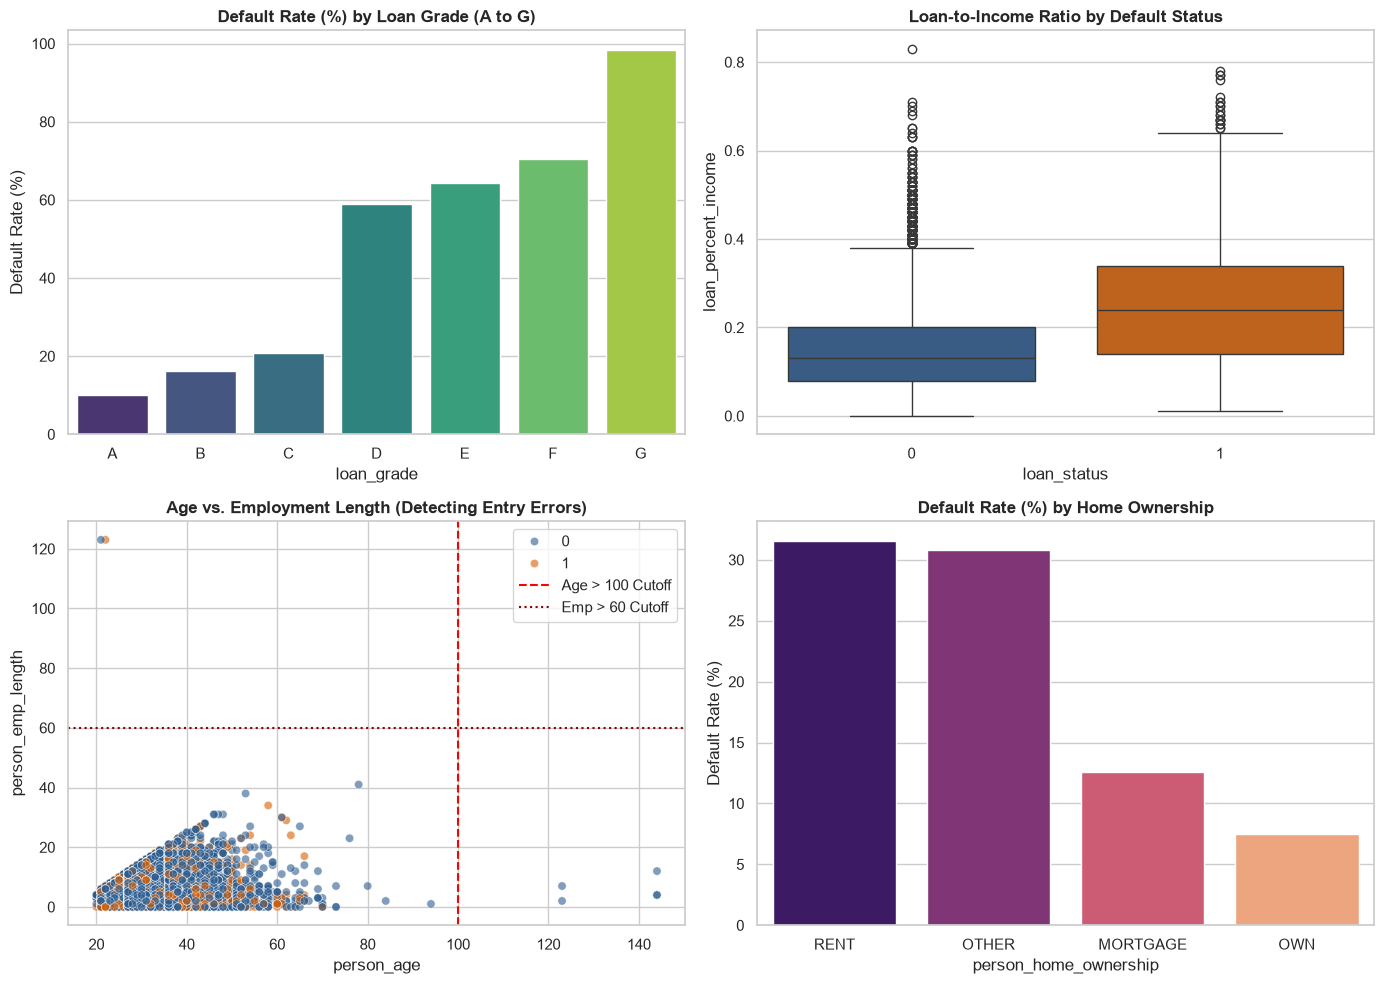

In [3]:
print("Target Variable ('loan_status') Distribution (0 = Non-Default, 1 = Default):")
display(pd.DataFrame({
    "Count": df_raw["loan_status"].value_counts(),
    "Percentage (%)": (df_raw["loan_status"].value_counts(normalize=True) * 100).round(2)
}))

num_cols_raw = df_raw.select_dtypes(include=["int64", "float64"]).drop(columns=["loan_status"]).columns
desc = df_raw[num_cols_raw].describe().T[["count", "mean", "std", "min", "50%", "max"]]
desc["skewness"] = df_raw[num_cols_raw].skew()

iqr_outliers = []
for col in num_cols_raw:
    s = df_raw[col].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    iqr_outliers.append(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())
desc["IQR_Outliers"] = iqr_outliers
display(desc.round(2))

# Inspect biologically/logically impossible records
impossible_age = df_raw[df_raw["person_age"] > 100]
impossible_emp = df_raw[
    (df_raw["person_emp_length"] > 60) | (df_raw["person_emp_length"] > df_raw["person_age"] - 14)
]
print(f"Anomalous rows with person_age > 100               : {len(impossible_age)} rows (Max age: {df_raw['person_age'].max()})")
print(f"Anomalous rows with impossible employment length   : {len(impossible_emp)} rows (Max emp_length: {df_raw['person_emp_length'].max()})")
display(pd.concat([impossible_age, impossible_emp]).drop_duplicates().head(10))

# Visual EDA Dashboard
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Default rate by Loan Grade
grade_order = sorted(df_raw["loan_grade"].unique())
grade_default = df_raw.groupby("loan_grade")["loan_status"].mean().loc[grade_order] * 100
sns.barplot(x=grade_default.index, y=grade_default.values, palette="viridis", ax=axes[0, 0])
axes[0, 0].set_title("Default Rate (%) by Loan Grade (A to G)", fontweight="bold")
axes[0, 0].set_ylabel("Default Rate (%)")

# 2. Loan Percent Income vs Default Status
sns.boxplot(data=df_raw, x="loan_status", y="loan_percent_income", palette=["#2b5c8f", "#d95f02"], ax=axes[0, 1])
axes[0, 1].set_title("Loan-to-Income Ratio by Default Status", fontweight="bold")

# 3. Age vs Employment Length Scatter (Highlighting Impossible Outliers)
sns.scatterplot(
    data=df_raw, x="person_age", y="person_emp_length", hue="loan_status",
    palette=["#2b5c8f", "#d95f02"], alpha=0.6, ax=axes[1, 0]
)
axes[1, 0].axvline(100, color="red", linestyle="--", label="Age > 100 Cutoff")
axes[1, 0].axhline(60, color="darkred", linestyle=":", label="Emp > 60 Cutoff")
axes[1, 0].set_title("Age vs. Employment Length (Detecting Entry Errors)", fontweight="bold")
axes[1, 0].legend()

# 4. Default rate by Home Ownership
home_default = df_raw.groupby("person_home_ownership")["loan_status"].mean().sort_values(ascending=False) * 100
sns.barplot(x=home_default.index, y=home_default.values, palette="magma", ax=axes[1, 1])
axes[1, 1].set_title("Default Rate (%) by Home Ownership", fontweight="bold")
axes[1, 1].set_ylabel("Default Rate (%)")

plt.tight_layout()
plt.savefig("outputs/eda_credit_risk.png", dpi=150)
plt.show()

# Evidence-Based Data Cleaning

In [4]:
"""
Cleaning Rules Justified by EDA Findings:
1. Drop 165 exact duplicate rows discovered in Cell 2.
2. Filter out biologically/logically impossible data entry errors discovered in Cell 3:
   - person_age > 100 (e.g., 123 and 144 years old)
   - person_emp_length > 60 or employment length exceeding (person_age - 14)
3. Preserve NaN values in 'loan_int_rate' and 'person_emp_length' to be imputed INSIDE
   the cross-validated Scikit-Learn Pipeline (after train/test split) to prevent data leakage,
   while adding explicit missingness indicator flags.
"""
df_clean = df_raw.copy()

initial_rows = len(df_clean)
df_clean.drop_duplicates(inplace=True)
after_dedup_rows = len(df_clean)

valid_age_mask = df_clean["person_age"] <= 100
valid_emp_mask = df_clean["person_emp_length"].isna() | (
    (df_clean["person_emp_length"] <= 60) &
    (df_clean["person_emp_length"] <= (df_clean["person_age"] - 14))
)
df_clean = df_clean[valid_age_mask & valid_emp_mask].reset_index(drop=True)

print(f"Initial Raw Rows          : {initial_rows:,}")
print(f"Removed Exact Duplicates  : {initial_rows - after_dedup_rows:,}")
print(f"Removed Impossible Errors : {after_dedup_rows - len(df_clean):,}")
print(f"Final Cleaned Rows        : {len(df_clean):,}")

Initial Raw Rows          : 32,581
Removed Exact Duplicates  : 165
Removed Impossible Errors : 7
Final Cleaned Rows        : 32,409


# Domain Feature Engineering & Leak-Free Preprocessing

In [5]:
df_feat = df_clean.copy()

# 1. Missingness indicator flags (captures whether missing rate/employment carries signal)
df_feat["is_int_rate_missing"] = df_feat["loan_int_rate"].isna().astype(int)
df_feat["is_emp_length_missing"] = df_feat["person_emp_length"].isna().astype(int)

# 2. Log-transform highly skewed income (skewness > 30 in raw data)
df_feat["log_person_income"] = np.log1p(df_feat["person_income"])

# 3. Loan-to-Income discrepancy check (loan_amnt / person_income vs reported loan_percent_income)
df_feat["computed_loan_to_income"] = df_feat["loan_amnt"] / (df_feat["person_income"] + 1.0)

# 4. Credit history intensity relative to adult years
adult_years = np.maximum(df_feat["person_age"] - 18, 1)
df_feat["cred_hist_to_adult_age_ratio"] = df_feat["cb_person_cred_hist_length"] / adult_years

# 5. Map binary default history ('Y'/'N') to 1/0
df_feat["cb_person_default_on_file"] = df_feat["cb_person_default_on_file"].map({"Y": 1, "N": 0}).astype(int)

X = df_feat.drop(columns=["loan_status"])
y = df_feat["loan_status"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

def build_preprocessor(df_input):
    ordinal_cols = ["loan_grade"]
    nominal_cols = ["person_home_ownership", "loan_intent"]
    num_cols = [c for c in df_input.columns if c not in ordinal_cols + nominal_cols]

    num_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    ord_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ordinal", OrdinalEncoder(categories=[["A", "B", "C", "D", "E", "F", "G"]])),
    ])
    nom_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])

    return ColumnTransformer(transformers=[
        ("num", num_pipe, num_cols),
        ("ord", ord_pipe, ordinal_cols),
        ("nom", nom_pipe, nominal_cols),
    ])

print(f"Train Set: {X_train.shape} | Test Set: {X_test.shape}")

Train Set: (25927, 16) | Test Set: (6482, 16)


# Model Benchmarking (Logistic Regression vs. LightGBM) & KS-Statistic

In [6]:
def compute_ks_statistic(y_true, y_probs):
    """Compute Kolmogorov-Smirnov (KS) statistic separating Default vs Non-Default distributions."""
    probs_default = y_probs[y_true == 1]
    probs_non_default = y_probs[y_true == 0]
    ks_stat, _ = ks_2samp(probs_default, probs_non_default)
    return float(ks_stat)

def find_optimal_f1_threshold(y_true, y_probs):
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_probs)
    f1_scores = (2 * precisions * recalls) / (precisions + recalls + 1e-8)
    best_idx = np.argmax(f1_scores[:-1])
    return float(thresholds[best_idx])

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    "Logistic Regression (Baseline)": Pipeline([
        ("preprocessor", build_preprocessor(X_train)),
        ("classifier", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)),
    ]),
    "LightGBM (Credit Scoring GBDT)": Pipeline([
        ("preprocessor", build_preprocessor(X_train)),
        ("classifier", LGBMClassifier(
            n_estimators=350,
            learning_rate=0.05,
            num_leaves=31,
            max_depth=6,
            subsample_for_bin=50000,
            subsample=0.8,
            colsample_bytree=0.8,
            scale_pos_weight=scale_pos_weight,
            random_state=42,
            verbose=-1,
        )),
    ]),
}

best_model, best_pr_auc = None, 0.0

for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    y_probs = pipeline.predict_proba(X_test)[:, 1]
    opt_thresh = find_optimal_f1_threshold(y_test, y_probs)
    y_pred = (y_probs >= opt_thresh).astype(int)

    roc_auc = roc_auc_score(y_test, y_probs)
    pr_auc = average_precision_score(y_test, y_probs)
    ks_stat = compute_ks_statistic(y_test, y_probs)

    print(f"\n---> {name}")
    print(f"ROC-AUC : {roc_auc:.4f} | PR-AUC : {pr_auc:.4f} | KS-Stat : {ks_stat:.4f} | Optimal Threshold : {opt_thresh:.4f}")
    print(classification_report(y_test, y_pred, target_names=["Non-Default (0)", "Default (1)"]))

    # Select best model based on PR-AUC (primary metric for imbalanced credit default)
    if pr_auc > best_pr_auc:
        best_pr_auc = pr_auc
        best_model = pipeline

joblib.dump(best_model, "outputs/best_credit_risk_model.joblib")


---> Logistic Regression (Baseline)
ROC-AUC : 0.8785 | PR-AUC : 0.7130 | KS-Stat : 0.6064 | Optimal Threshold : 0.6349
                 precision    recall  f1-score   support

Non-Default (0)       0.91      0.88      0.90      5064
    Default (1)       0.62      0.70      0.66      1418

       accuracy                           0.84      6482
      macro avg       0.77      0.79      0.78      6482
   weighted avg       0.85      0.84      0.85      6482


---> LightGBM (Credit Scoring GBDT)
ROC-AUC : 0.9533 | PR-AUC : 0.9131 | KS-Stat : 0.7747 | Optimal Threshold : 0.6596
                 precision    recall  f1-score   support

Non-Default (0)       0.94      0.99      0.96      5064
    Default (1)       0.95      0.77      0.85      1418

       accuracy                           0.94      6482
      macro avg       0.94      0.88      0.90      6482
   weighted avg       0.94      0.94      0.94      6482



['outputs/best_credit_risk_model.joblib']

# SHAP Explainability for Credit Risk Decisions

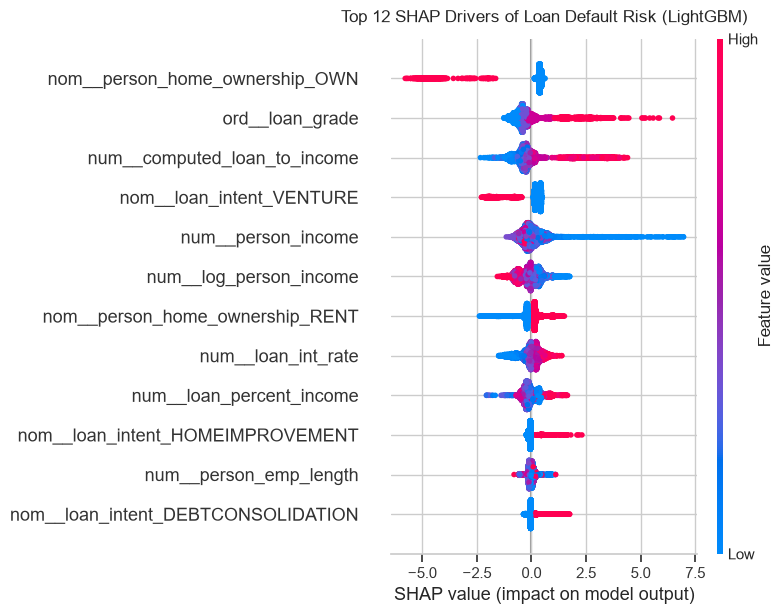

In [7]:
lgbm_pipe = models["LightGBM (Credit Scoring GBDT)"]
X_test_transformed = lgbm_pipe.named_steps["preprocessor"].transform(X_test)
feature_names = lgbm_pipe.named_steps["preprocessor"].get_feature_names_out()

explainer = shap.TreeExplainer(lgbm_pipe.named_steps["classifier"])
shap_values = explainer.shap_values(X_test_transformed)

# Handle LightGBM binary SHAP output format across SHAP versions
shap_vals_to_plot = shap_values[1] if isinstance(shap_values, list) else shap_values

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals_to_plot, X_test_transformed, feature_names=feature_names, show=False, max_display=12)
plt.title("Top 12 SHAP Drivers of Loan Default Risk (LightGBM)", fontsize=12, pad=12)
plt.tight_layout()
plt.savefig("outputs/shap_credit_risk.png", dpi=150)
plt.show()

# Experiment: Adding 'rent_high_dti' Interaction Feature

In [8]:
df_exp2 = df_feat.copy()
df_exp2["rent_high_dti"] = (
    (df_exp2["person_home_ownership"] == "RENT") & (df_exp2["loan_percent_income"] > 0.30)
).astype(int)

X_exp = df_exp2.drop(columns=["loan_status"])
y_exp = df_exp2["loan_status"].values
X_tr2, X_te2, y_tr2, y_te2 = train_test_split(X_exp, y_exp, test_size=0.2, random_state=42, stratify=y_exp)

spw2 = (y_tr2 == 0).sum() / (y_tr2 == 1).sum()
lgbm_exp2 = Pipeline([
    ("preprocessor", build_preprocessor(X_tr2)),
    ("classifier", LGBMClassifier(
        n_estimators=350, learning_rate=0.05, num_leaves=31, max_depth=6,
        subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw2, random_state=42, verbose=-1
    )),
])
lgbm_exp2.fit(X_tr2, y_tr2)
probs_exp2 = lgbm_exp2.predict_proba(X_te2)[:, 1]

orig_probs = models["LightGBM (Credit Scoring GBDT)"].predict_proba(X_test)[:, 1]
print(f"Original LightGBM PR-AUC      : {average_precision_score(y_test, orig_probs):.4f} | ROC-AUC : {roc_auc_score(y_test, orig_probs):.4f}")
print(f"With 'rent_high_dti' PR-AUC   : {average_precision_score(y_te2, probs_exp2):.4f} | ROC-AUC : {roc_auc_score(y_te2, probs_exp2):.4f}")

# Check SHAP ranking of 'rent_high_dti'
X_te2_sample = X_te2.sample(800, random_state=42)
X_te2_trans = lgbm_exp2.named_steps["preprocessor"].transform(X_te2_sample)
feat_names2 = lgbm_exp2.named_steps["preprocessor"].get_feature_names_out()
sv2 = shap.TreeExplainer(lgbm_exp2.named_steps["classifier"]).shap_values(X_te2_trans)
sv2_plot = sv2[1] if isinstance(sv2, list) else sv2

mean_abs_shap = pd.Series(np.abs(sv2_plot).mean(axis=0), index=feat_names2).sort_values(ascending=False)
rank_pos = list(mean_abs_shap.index).index("num__rent_high_dti") + 1
print(f"'num__rent_high_dti' SHAP Importance Rank: #{rank_pos} out of {len(mean_abs_shap)} features")
display(mean_abs_shap.head(12).round(4).to_frame("Mean_Abs_SHAP"))


Original LightGBM PR-AUC      : 0.9131 | ROC-AUC : 0.9533
With 'rent_high_dti' PR-AUC   : 0.9142 | ROC-AUC : 0.9543
'num__rent_high_dti' SHAP Importance Rank: #1 out of 25 features


,Mean_Abs_SHAP
num__rent_high_dti,1.0820
ord__loan_grade,0.6843
nom__person_home_ownership_OWN,0.6513
nom__loan_intent_VENTURE,0.5688
num__person_income,0.4791
num__computed_loan_to_income,0.4766
num__loan_int_rate,0.3328
num__loan_percent_income,0.2843
num__log_person_income,0.2799
nom__loan_intent_HOMEIMPROVEMENT,0.1303
